# Interactive Notebook: CNN Training, Backpropagation, Evaluation, and Weight Persistence  
## NumPy-Based Learning Loop for Image Classification

Welcome to this lesson.

In the previous Computer Vision lesson, you learned how images are represented as matrices and how CNNs use filters to detect visual patterns.

In this notebook, you will go deeper into how a model learns.

---

## Learning Objectives

By the end of this notebook, you should be able to:

1. Explain how backpropagation sends error backward through a model.
2. Implement backward methods for dense and convolution-style layers using NumPy.
3. Build a complete training loop using gradient descent.
4. Evaluate model performance using accuracy.
5. Generate and interpret a confusion matrix.
6. Identify common misclassification errors.
7. Save and load trained weights using `np.save()` and `np.load()`.
8. Run inference using saved weights without retraining.

# Part 1: The Full Training Loop

A model does not learn by only making predictions.

It learns through a repeated loop:

```text
Forward Pass
↓
Compute Loss
↓
Backward Pass
↓
Update Weights
↓
Repeat
```

This is what libraries like TensorFlow and PyTorch automate.

In this notebook, we will build the core ideas ourselves using NumPy.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

print("NumPy version:", np.__version__)

NumPy version: 2.5.3


# Part 2: Tiny Dense Layer Example

Before working with image data, we will start with a small dense layer.

A dense layer uses this formula:

```python
output = input @ weights + bias
```

Where:

- `input` is the data
- `weights` are learnable parameters
- `bias` is a learnable offset
- `@` means matrix multiplication

In [2]:
# One input example with 3 features
X = np.array([[1.0, 2.0, 3.0]])

# Dense layer with 3 inputs and 2 outputs
W = np.array([
    [0.1, 0.2],
    [0.3, 0.4],
    [0.5, 0.6]
])

b = np.array([[0.1, -0.1]])

output = X @ W + b

print("Input shape:", X.shape)
print("Weights shape:", W.shape)
print("Bias shape:", b.shape)
print("Output:", output)
print("Output shape:", output.shape)

Input shape: (1, 3)
Weights shape: (3, 2)
Bias shape: (1, 2)
Output: [[2.3 2.7]]
Output shape: (1, 2)


# Part 3: Backpropagation for a Dense Layer

During the backward pass, we calculate gradients.

If:

```python
output = input @ weights + bias
```

Then the main gradients are:

```python
dW = input.T @ d_output
db = sum(d_output)
dX = d_output @ weights.T
```

Meaning:

- `dW` tells how weights should change
- `db` tells how biases should change
- `dX` sends the gradient backward to the previous layer

In [3]:
# Suppose this is the gradient coming from the next layer
d_output = np.array([[1.0, -1.0]])

dW = X.T @ d_output
db = np.sum(d_output, axis=0, keepdims=True)
dX = d_output @ W.T

print("dW:")
print(dW)

print("\ndb:")
print(db)

print("\ndX:")
print(dX)

dW:
[[ 1. -1.]
 [ 2. -2.]
 [ 3. -3.]]

db:
[[ 1. -1.]]

dX:
[[-0.1 -0.1 -0.1]]


## Practice 1: Dense Layer Gradients

Change the values of `X`, `W`, and `d_output`.

Then answer:

1. What is the shape of `dW`?
2. What is the shape of `db`?
3. What is the shape of `dX`?
4. Why does `dX` matter?

In [4]:
# Practice 1

X_practice = np.array([[2.0, 1.0, 0.9]])
W_practice = np.array([
    [0.2, -0.1],
    [0.4,  0.3],
    [0.1,  0.5]
])
d_output_practice = np.array([[0.5, -0.2]])

# Calculate gradients below
dW_practice = X_practice.T @ d_output_practice
db_practice = np.sum(d_output_practice, axis=0, keepdims=True)
dX_practice = d_output_practice @ W_practice.T

print("dW shape:", dW_practice.shape)
print("db shape:", db_practice.shape)
print("dX shape:", dX_practice.shape)
print("dW:")
print(dW_practice)

dW shape: (3, 2)
db shape: (1, 2)
dX shape: (1, 3)
dW:
[[ 1.   -0.4 ]
 [ 0.5  -0.2 ]
 [ 0.45 -0.18]]


# Part 4: Building a Dense Layer Class

Now we will create a reusable Dense layer class.

It will have:

- `forward()`
- `backward()`
- `update()`

This mirrors the structure of real deep learning libraries.

In [5]:
class DenseLayer:
    def __init__(self, input_size, output_size):
        self.weights = np.random.randn(input_size, output_size) * 0.01
        self.biases = np.zeros((1, output_size))

    def forward(self, inputs):
        self.inputs = inputs
        self.output = inputs @ self.weights + self.biases
        return self.output

    def backward(self, d_output):
        self.d_weights = self.inputs.T @ d_output
        self.d_biases = np.sum(d_output, axis=0, keepdims=True)
        self.d_inputs = d_output @ self.weights.T
        return self.d_inputs

    def update(self, learning_rate):
        self.weights -= learning_rate * self.d_weights
        self.biases -= learning_rate * self.d_biases

In [6]:
dense = DenseLayer(input_size=3, output_size=2)

X_sample = np.array([[1.0, 2.0, 3.0]])
out = dense.forward(X_sample)

print("Forward output:")
print(out)

d_out = np.array([[1.0, -1.0]])
d_inputs = dense.backward(d_out)

print("\nWeight gradients:")
print(dense.d_weights)

print("\nBias gradients:")
print(dense.d_biases)

print("\nGradient passed backward:")
print(d_inputs)

Forward output:
[[0.01089631 0.02205385]]

Weight gradients:
[[ 1. -1.]
 [ 2. -2.]
 [ 3. -3.]]

Bias gradients:
[[ 1. -1.]]

Gradient passed backward:
[[ 6.34978454e-03 -8.75341318e-03 -1.64177742e-07]]


# Part 5: Activation Functions and Their Gradients

Neural networks use activation functions to learn non-linear patterns.

We will use ReLU:

```python
ReLU(x) = max(0, x)
```

Its gradient is:

```text
1 if x > 0
0 if x <= 0
```

In [7]:
class ReLU:
    def forward(self, inputs):
        self.inputs = inputs
        return np.maximum(0, inputs)

    def backward(self, d_output):
        d_inputs = d_output.copy()
        d_inputs[self.inputs <= 0] = 0
        return d_inputs

In [8]:
relu = ReLU()

values = np.array([[-2, -1, 0, 1, 2]])
activated = relu.forward(values)

print("Original values:")
print(values)

print("\nAfter ReLU:")
print(activated)

gradient = relu.backward(np.ones_like(values))

print("\nReLU gradient:")
print(gradient)

Original values:
[[-2 -1  0  1  2]]

After ReLU:
[[0 0 0 1 2]]

ReLU gradient:
[[0 0 0 1 1]]


# Part 6: Softmax and Cross-Entropy Loss

For digit classification, the model outputs 10 scores, one for each digit.

Softmax turns those scores into probabilities.

Cross-entropy loss measures how wrong the predicted probabilities are.

In [9]:
def softmax(logits):
    shifted_logits = logits - np.max(logits, axis=1, keepdims=True)
    exp_values = np.exp(shifted_logits)
    probabilities = exp_values / np.sum(exp_values, axis=1, keepdims=True)
    return probabilities

def cross_entropy_loss(probabilities, y_true):
    n_samples = probabilities.shape[0]
    correct_probs = probabilities[range(n_samples), y_true]
    loss = -np.mean(np.log(correct_probs + 1e-9))
    return loss

def softmax_cross_entropy_backward(probabilities, y_true):
    n_samples = probabilities.shape[0]
    d_logits = probabilities.copy()
    d_logits[range(n_samples), y_true] -= 1
    d_logits = d_logits / n_samples
    return d_logits

In [10]:
logits = np.array([[2.0, 1.0, 0.1]])
y_true = np.array([0])

probs = softmax(logits)
loss = cross_entropy_loss(probs, y_true)
d_logits = softmax_cross_entropy_backward(probs, y_true)

print("Probabilities:")
print(probs)

print("\nLoss:", loss)

print("\nGradient of loss with respect to logits:")
print(d_logits)

Probabilities:
[[0.65900114 0.24243297 0.09856589]]

Loss: 0.4170300147603855

Gradient of loss with respect to logits:
[[-0.34099886  0.24243297  0.09856589]]


# Part 7: Load MNIST Data

Now we will use MNIST digits.

To keep this notebook fast enough for class, we will use a smaller subset of the data.

This keeps the focus on understanding the training loop, not waiting for long training.

In [11]:
from tensorflow.keras.datasets import mnist

(X_train_full, y_train_full), (X_test_full, y_test_full) = mnist.load_data()

# Normalize images
X_train_full = X_train_full / 255.0
X_test_full = X_test_full / 255.0

# Use smaller subsets for faster NumPy training
train_size = 2000
test_size = 500

X_train = X_train_full[:train_size]
y_train = y_train_full[:train_size]

X_test = X_test_full[:test_size]
y_test = y_test_full[:test_size]

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

Training images: (2000, 28, 28)
Training labels: (2000,)
Testing images: (500, 28, 28)
Testing labels: (500,)


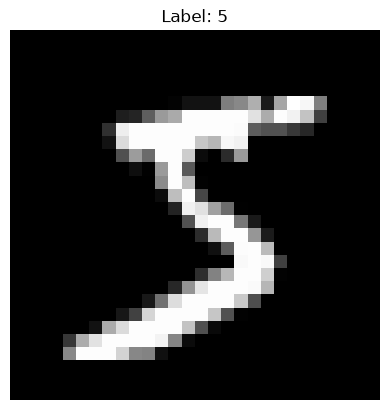

In [12]:
index = 0

plt.imshow(X_train[index], cmap="gray")
plt.title(f"Label: {y_train[index]}")
plt.axis("off")
plt.show()

# Part 8: A Simple NumPy Image Classifier

A full NumPy CNN is mathematically heavy.

So we will first build a clear NumPy training loop using a simple image classifier:

```text
28x28 image
↓
Flatten to 784 values
↓
Dense layer
↓
ReLU
↓
Dense layer
↓
Softmax
↓
Digit prediction
```

This lets us clearly implement:

- forward pass
- loss
- backward pass
- weight updates
- accuracy
- confusion matrix
- saving/loading weights

Then we will include a convolution-style filter practice section.

In [13]:
# Flatten images
X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_test_flat = X_test.reshape(X_test.shape[0], -1)

print("Flattened training shape:", X_train_flat.shape)
print("Flattened testing shape:", X_test_flat.shape)

Flattened training shape: (2000, 784)
Flattened testing shape: (500, 784)


# Part 9: Build the NumPy Model

The model will have:

```text
Dense(784 → 64)
ReLU
Dense(64 → 10)
Softmax
```

In [14]:
class SimpleNumPyClassifier:
    def __init__(self):
        self.dense1 = DenseLayer(784, 64)
        self.relu1 = ReLU()
        self.dense2 = DenseLayer(64, 10)

    def forward(self, X):
        z1 = self.dense1.forward(X)
        a1 = self.relu1.forward(z1)
        logits = self.dense2.forward(a1)
        probabilities = softmax(logits)
        return probabilities

    def backward(self, d_logits):
        d_hidden = self.dense2.backward(d_logits)
        d_hidden_relu = self.relu1.backward(d_hidden)
        self.dense1.backward(d_hidden_relu)

    def update(self, learning_rate):
        self.dense1.update(learning_rate)
        self.dense2.update(learning_rate)

    def predict(self, X):
        probabilities = self.forward(X)
        return np.argmax(probabilities, axis=1)

In [15]:
model = SimpleNumPyClassifier()

sample_probs = model.forward(X_train_flat[:5])

print("Prediction probabilities shape:", sample_probs.shape)
print("Predicted labels:", np.argmax(sample_probs, axis=1))
print("Actual labels:", y_train[:5])

Prediction probabilities shape: (5, 10)
Predicted labels: [5 7 5 3 7]
Actual labels: [5 0 4 1 9]


# Part 10: Accuracy Function

Accuracy is:

```text
correct predictions / total predictions
```

In [16]:
def calculate_accuracy(y_true, y_pred):
    return np.mean(y_true == y_pred)

preds = model.predict(X_train_flat[:100])
acc = calculate_accuracy(y_train[:100], preds)

print("Initial accuracy before training:", acc)

Initial accuracy before training: 0.09


# Part 11: Mini-Batch Training Loop

Training on all samples at once can be slow.

A mini-batch means we train using a smaller group of examples at a time.

Each batch follows:

```text
Forward → Loss → Backward → Update
```

In [17]:
def create_batches(X, y, batch_size):
    indices = np.arange(X.shape[0])
    np.random.shuffle(indices)

    for start in range(0, X.shape[0], batch_size):
        end = start + batch_size
        batch_indices = indices[start:end]
        yield X[batch_indices], y[batch_indices]

In [18]:
def train(model, X_train, y_train, X_test, y_test, epochs=5, batch_size=64, learning_rate=0.1):
    history = {
        "loss": [],
        "train_accuracy": [],
        "test_accuracy": []
    }

    for epoch in range(epochs):
        batch_losses = []

        for X_batch, y_batch in create_batches(X_train, y_train, batch_size):
            # Forward pass
            probabilities = model.forward(X_batch)

            # Compute loss
            loss = cross_entropy_loss(probabilities, y_batch)
            batch_losses.append(loss)

            # Backward pass
            d_logits = softmax_cross_entropy_backward(probabilities, y_batch)
            model.backward(d_logits)

            # Update weights
            model.update(learning_rate)

        # Epoch metrics
        avg_loss = np.mean(batch_losses)

        train_preds = model.predict(X_train)
        test_preds = model.predict(X_test)

        train_acc = calculate_accuracy(y_train, train_preds)
        test_acc = calculate_accuracy(y_test, test_preds)

        history["loss"].append(avg_loss)
        history["train_accuracy"].append(train_acc)
        history["test_accuracy"].append(test_acc)

        print(f"Epoch {epoch+1}/{epochs} | Loss: {avg_loss:.4f} | Train Acc: {train_acc:.4f} | Test Acc: {test_acc:.4f}")

    return history

## Train the Model

Run the cell below.

You should see loss generally decrease and accuracy generally improve.

Because this is a simple NumPy model trained on a small subset, it will not be perfect. That is okay. The goal is to understand the learning process.

In [19]:
model = SimpleNumPyClassifier()

history = train(
    model,
    X_train_flat,
    y_train,
    X_test_flat,
    y_test,
    epochs=8,
    batch_size=64,
    learning_rate=0.1
)

Epoch 1/8 | Loss: 2.2866 | Train Acc: 0.5095 | Test Acc: 0.4800
Epoch 2/8 | Loss: 2.1030 | Train Acc: 0.4470 | Test Acc: 0.4140
Epoch 3/8 | Loss: 1.4882 | Train Acc: 0.7300 | Test Acc: 0.6600
Epoch 4/8 | Loss: 0.9273 | Train Acc: 0.8165 | Test Acc: 0.7440
Epoch 5/8 | Loss: 0.6903 | Train Acc: 0.8185 | Test Acc: 0.7720
Epoch 6/8 | Loss: 0.5684 | Train Acc: 0.8465 | Test Acc: 0.7740
Epoch 7/8 | Loss: 0.4906 | Train Acc: 0.8705 | Test Acc: 0.8100
Epoch 8/8 | Loss: 0.4515 | Train Acc: 0.8735 | Test Acc: 0.8020


# Part 12: Plot Training Progress

Let's visualize loss and accuracy over epochs.

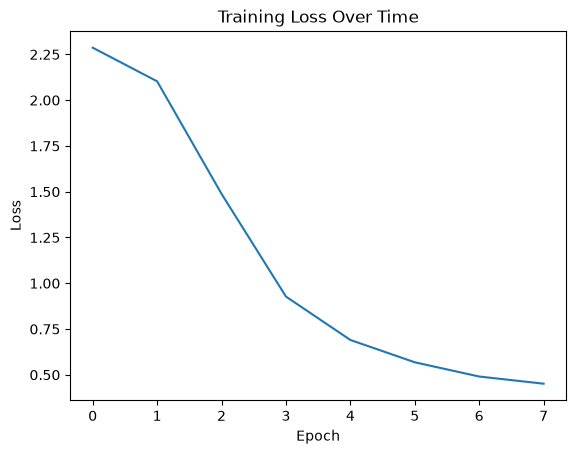

In [20]:
plt.plot(history["loss"])
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss Over Time")
plt.show()

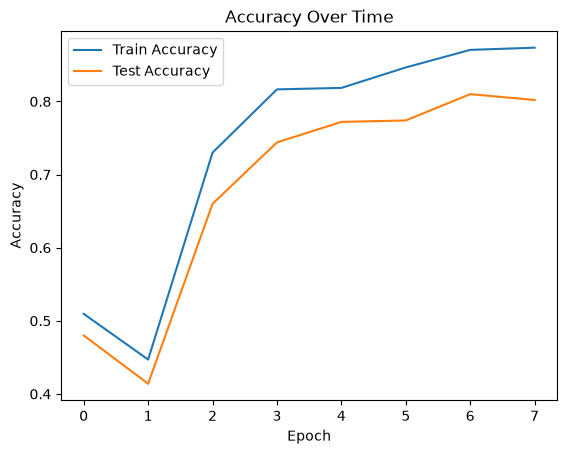

In [21]:
plt.plot(history["train_accuracy"], label="Train Accuracy")
plt.plot(history["test_accuracy"], label="Test Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy Over Time")
plt.legend()
plt.show()

# Part 13: Generalization and Overfitting

The training set is used to learn weights.

The test set checks performance on unseen data.

If training accuracy is high but test accuracy is much lower, the model may be overfitting.

Overfitting means:

```text
The model memorized training examples instead of learning patterns that generalize.
```

## Practice 1: Interpret the Curves

Look at your accuracy plot.

Answer:

1. Did training accuracy improve?
2. Did test accuracy improve?
3. Is there a large gap between training and test accuracy?
4. Does the model seem to generalize?

In [22]:
# Practice 1: Write answers as comments

# 1.
# 2.
# 3.
# 4.

# Part 14: Test Performance

Now let's calculate final test accuracy.

In [23]:
test_predictions = model.predict(X_test_flat)
test_accuracy = calculate_accuracy(y_test, test_predictions)

print("Final Test Accuracy:", test_accuracy)
print("Final Test Accuracy (%):", round(test_accuracy * 100, 2))

Final Test Accuracy: 0.802
Final Test Accuracy (%): 80.2


# Part 15: Confusion Matrix

A confusion matrix shows which classes the model gets right and which classes it confuses.

For MNIST, rows represent actual digits and columns represent predicted digits.

Example:

```text
row 4, column 9 = number of times an actual 4 was predicted as 9
```

In [24]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, test_predictions)

print(cm)

[[36  0  1  0  0  5  0  0  0  0]
 [ 0 65  0  0  0  2  0  0  0  0]
 [ 0  0 48  0  1  0  2  3  1  0]
 [ 0  0  1 22  0 18  0  3  1  0]
 [ 0  0  0  0 52  0  3  0  0  0]
 [ 1  0  0  0  1 42  2  3  0  1]
 [ 1  0  3  0  4  3 32  0  0  0]
 [ 0  0  2  0  1  0  0 45  0  1]
 [ 0  0  0  0  2  5  1  2 28  2]
 [ 0  0  1  1 12  2  0  6  1 31]]


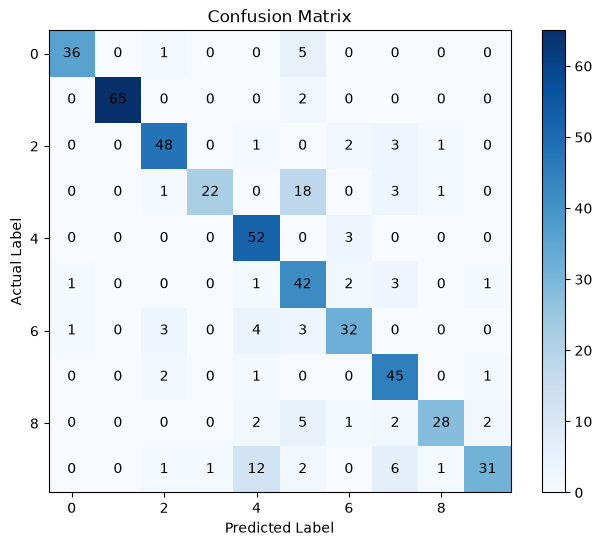

In [25]:
plt.figure(figsize=(8, 6))
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.colorbar()

for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha="center", va="center", color="black")

plt.show()

# Part 16: Find the Top 3 Misclassification Pairs

We want to identify which digit pairs the model confuses most often.

Example:

```text
Actual 4 predicted as 9
Actual 3 predicted as 8
```

In [26]:
pairs = []

for actual in range(10):
    for predicted in range(10):
        if actual != predicted:
            count = cm[actual, predicted]
            pairs.append((count, actual, predicted))

pairs = sorted(pairs, reverse=True)

print("Top 3 misclassification pairs:")
for count, actual, predicted in pairs[:3]:
    print(f"Actual {actual} predicted as {predicted}: {count} times")

Top 3 misclassification pairs:
Actual 3 predicted as 5: 18 times
Actual 9 predicted as 4: 12 times
Actual 9 predicted as 7: 6 times


# Part 17: Visual Inspection of Misclassified Images

Numbers alone do not tell the full story.

We should look at the images the model got wrong.

Ask:

- Is the digit clear?
- Is the digit messy?
- Could a human also be confused?
- Is the digit off-center?

Number of misclassified test images: 99


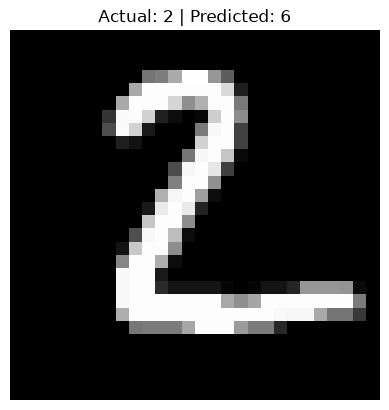

In [27]:
misclassified_indices = np.where(test_predictions != y_test)[0]

print("Number of misclassified test images:", len(misclassified_indices))

if len(misclassified_indices) > 0:
    index = misclassified_indices[0]

    plt.imshow(X_test[index], cmap="gray")
    plt.title(f"Actual: {y_test[index]} | Predicted: {test_predictions[index]}")
    plt.axis("off")
    plt.show()

## Practice 2: Inspect More Errors

Change `error_number` to inspect different misclassified examples.

Try:

```python
error_number = 0
error_number = 1
error_number = 2
error_number = 3
```

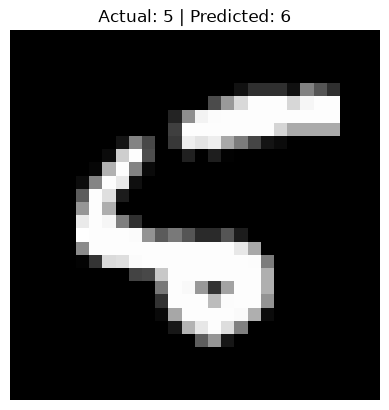

In [28]:
# Practice 2

error_number = 1

if len(misclassified_indices) > error_number:
    index = misclassified_indices[error_number]

    plt.imshow(X_test[index], cmap="gray")
    plt.title(f"Actual: {y_test[index]} | Predicted: {test_predictions[index]}")
    plt.axis("off")
    plt.show()
else:
    print("Not enough misclassified examples to show this error number.")

# Part 18: Convolutional Layer Backpropagation Concept

A convolutional filter slides across image patches.

During the forward pass:

```text
patch × filter → output value
```

During the backward pass:

```text
output gradient tells how much each filter value contributed to the error
```

Because the same filter is reused across the image, gradients accumulate across all locations.

In [29]:
# Small image and filter example

small_img = np.array([
    [0, 0, 1, 1],
    [0, 1, 1, 0],
    [0, 0, 1, 1],
    [1, 1, 0, 0]
], dtype=float)

conv_filter = np.array([
    [1, 0],
    [0, -1]
], dtype=float)

print("Image:")
print(small_img)

print("\nFilter:")
print(conv_filter)

Image:
[[0. 0. 1. 1.]
 [0. 1. 1. 0.]
 [0. 0. 1. 1.]
 [1. 1. 0. 0.]]

Filter:
[[ 1.  0.]
 [ 0. -1.]]


In [30]:
def conv2d_forward_single(image, kernel):
    image_h, image_w = image.shape
    kernel_h, kernel_w = kernel.shape

    out_h = image_h - kernel_h + 1
    out_w = image_w - kernel_w + 1

    output = np.zeros((out_h, out_w))

    for i in range(out_h):
        for j in range(out_w):
            patch = image[i:i+kernel_h, j:j+kernel_w]
            output[i, j] = np.sum(patch * kernel)

    return output

conv_out = conv2d_forward_single(small_img, conv_filter)

print("Convolution output:")
print(conv_out)

Convolution output:
[[-1. -1.  1.]
 [ 0.  0.  0.]
 [-1.  0.  1.]]


In [31]:
def conv2d_filter_gradient_single(image, kernel, d_output):
    kernel_h, kernel_w = kernel.shape
    out_h, out_w = d_output.shape

    d_kernel = np.zeros_like(kernel)

    for i in range(out_h):
        for j in range(out_w):
            patch = image[i:i+kernel_h, j:j+kernel_w]
            d_kernel += patch * d_output[i, j]

    return d_kernel

# Suppose every output position contributed equally to the loss
d_output = np.ones_like(conv_out)

d_filter = conv2d_filter_gradient_single(small_img, conv_filter, d_output)

print("Gradient for filter:")
print(d_filter)

Gradient for filter:
[[4. 6.]
 [5. 5.]]


## Practice 3: Change the Output Gradient

Try changing `d_output`.

Questions:

1. What happens if some output positions have larger gradients?
2. Why does the filter gradient change?
3. Why do we add gradients from each image patch?

In [32]:
# Practice 3

custom_d_output = np.array([
    [1.0, 0.5, 0.0],
    [0.0, 1.0, 0.5],
    [0.5, 0.0, 1.0]
])

custom_d_filter = conv2d_filter_gradient_single(small_img, conv_filter, custom_d_output)

print("Custom d_output:")
print(custom_d_output)

print("\nCustom filter gradient:")
print(custom_d_filter)

Custom d_output:
[[1.  0.5 0. ]
 [0.  1.  0.5]
 [0.5 0.  1. ]]

Custom filter gradient:
[[2.5 2.5]
 [1.5 3.5]]


# Part 19: Weight Persistence

After training, we do not want to retrain the model every time.

We can save the trained weights and biases using NumPy.

This is called weight persistence.

Simple explanation:

```text
Saved weights = the trained brain of the model
```

In [33]:
# Save model parameters

np.save("dense1_weights.npy", model.dense1.weights)
np.save("dense1_biases.npy", model.dense1.biases)
np.save("dense2_weights.npy", model.dense2.weights)
np.save("dense2_biases.npy", model.dense2.biases)

print("Weights and biases saved.")

Weights and biases saved.


# Part 20: Load Weights into a New Model

Now we simulate a new session by creating a fresh model.

Then we load the saved weights into it.

If loading worked, the new model should make the same predictions.

In [34]:
loaded_model = SimpleNumPyClassifier()

loaded_model.dense1.weights = np.load("dense1_weights.npy")
loaded_model.dense1.biases = np.load("dense1_biases.npy")
loaded_model.dense2.weights = np.load("dense2_weights.npy")
loaded_model.dense2.biases = np.load("dense2_biases.npy")

loaded_predictions = loaded_model.predict(X_test_flat)

loaded_accuracy = calculate_accuracy(y_test, loaded_predictions)

print("Loaded model test accuracy:", loaded_accuracy)
print("Original model test accuracy:", test_accuracy)

Loaded model test accuracy: 0.802
Original model test accuracy: 0.802


# Part 21: Inference

Inference means using a trained model to make a prediction.

During inference, we only need:

```text
Forward Pass
```

We do not need:

```text
Loss
Backward Pass
Weight Updates
```

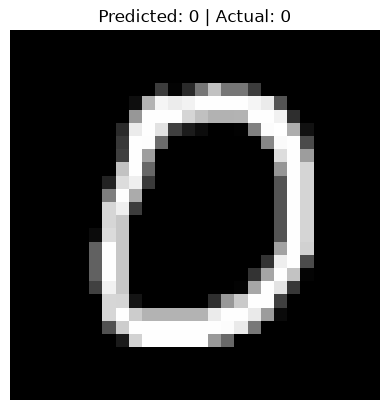

Prediction: 0
Actual: 0


In [35]:
index = 10

single_image = X_test_flat[index:index+1]

prediction = loaded_model.predict(single_image)[0]

plt.imshow(X_test[index], cmap="gray")
plt.title(f"Predicted: {prediction} | Actual: {y_test[index]}")
plt.axis("off")
plt.show()

print("Prediction:", prediction)
print("Actual:", y_test[index])

# Part 22: Independent Work

## Activity 1: Model Evaluation and Error Analysis

Goal: Quantify the model's performance on unseen data and identify classification errors.

Tasks:

1. Calculate test accuracy.
2. Review the confusion matrix.
3. Identify the digit pair with the highest number of misclassifications.
4. Display one image that the model misclassified.
5. Decide whether that image is visually clear or ambiguous.

---

## Activity 2: Model Persistence and Verification

Goal: Save and load trained parameters without retraining.

Tasks:

1. Use `np.save()` to save weights and biases.
2. Restart the kernel or create a new model.
3. Use `np.load()` to load weights and biases.
4. Run a prediction on a test image.
5. Confirm the model works without retraining.

# Final Reflection

Answer these questions:

1. What is the purpose of backpropagation?
2. What does a gradient tell us?
3. Why do we update weights using gradient descent?
4. Why do convolutional filter gradients accumulate across image patches?
5. What is the difference between training and inference?
6. Why do we need a test set?
7. What does overfitting mean?
8. What does a confusion matrix show?
9. Which digit pair did your model confuse most often?
10. Why is saving weights useful?

In [36]:
# Final Reflection Answers

# 1.
# 2.
# 3.
# 4.
# 5.
# 6.
# 7.
# 8.
# 9.
# 10.